MODULO 3 CAPITOLO 5 VIDEO 3 REGRESSIONE LINEARE IN PYTHON 

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing

In [3]:
data = fetch_california_housing(as_frame=True)
df = data.frame
print(f"Feature disponibili: {data.feature_names}")
print(df.head())
X= df[data.feature_names]
y = df["MedHouseVal"]




Feature disponibili: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
   MedInc  HouseAge  AveRooms  ...  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127  ...     37.88    -122.23        4.526
1  8.3014      21.0  6.238137  ...     37.86    -122.22        3.585
2  7.2574      52.0  8.288136  ...     37.85    -122.24        3.521
3  5.6431      52.0  5.817352  ...     37.85    -122.25        3.413
4  3.8462      52.0  6.281853  ...     37.85    -122.25        3.422

[5 rows x 9 columns]


In [4]:
model = LinearRegression()
model.fit(X,y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.44, 0.01,-0.11,...,-0. ,-0.42,-0.43]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-36.94
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [5]:
print(f"Intercetta: {model.intercept_}")
print(f"Feature Coefficientes:")
for name, coef in zip(data.feature_names, model.coef_):
    print(f"{name}: {coef:.4f}")
    

Intercetta: -36.94192020718454
Feature Coefficientes:
MedInc: 0.4367
HouseAge: 0.0094
AveRooms: -0.1073
AveBedrms: 0.6451
Population: -0.0000
AveOccup: -0.0038
Latitude: -0.4213
Longitude: -0.4345


In [6]:
y_pred = model.predict(X)


In [7]:
mae = np.mean(np.abs(y-y_pred))
print(f"MAE: {mae:.3f}")



MAE: 0.531


In [10]:
toll = 0.5
good_pred = np.mean(np.abs(y-y_pred) < toll)
print(f"Percentage Good Prediction: {good_pred * 100:.2f}")


Percentage Good Prediction: 58.82


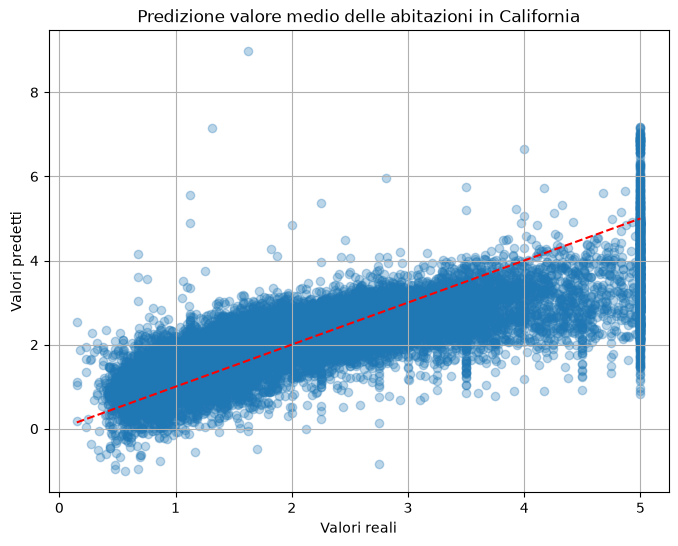

In [9]:
plt.figure(figsize=(8,6))
plt.scatter(y, y_pred, alpha = 0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = "red", linestyle="--")
plt.xlabel("Valori reali")
plt.ylabel("Valori predetti")
plt.title("Predizione valore medio delle abitazioni in California")
plt.grid()
plt.show()

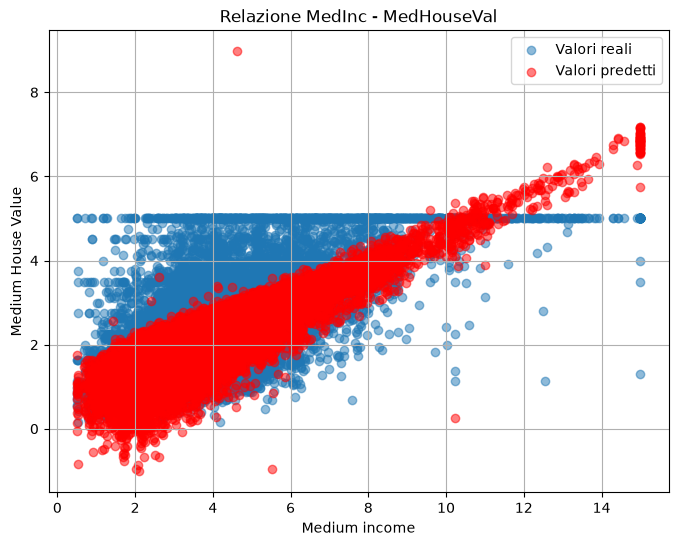

In [13]:
plt.figure(figsize=(8,6))
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha = 0.5, label = "Valori reali")
plt.scatter(df["MedInc"], y_pred, alpha = 0.5, color = "red", label = "Valori predetti")
plt.xlabel("Medium income")
plt.ylabel("Medium House Value")
plt.title("Relazione MedInc - MedHouseVal")
plt.legend()
plt.grid()
plt.show()

